In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import os

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load processed datasets
train_data = pd.read_csv("../data/train_processed.csv")
test_data = pd.read_csv("../data/test_processed.csv")

# Separate features and target
columns_to_drop = [
    "ID",
    "date",
    "calculated_day",
    "food_waste_kg"
]

X_train = train_data.drop(columns=columns_to_drop)
y_train = train_data["food_waste_kg"]

X_test = test_data.drop(columns=columns_to_drop)
y_test = test_data["food_waste_kg"]

# Verify the datasets
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nTesting features:", X_test.shape)
print("Testing target:", y_test.shape)

Training features: (737, 11)
Training target: (737,)

Testing features: (174, 11)
Testing target: (174,)


In [5]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category", "string"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'month', 'day_of_month']

Categorical features: ['staff_experience', 'waste_category']


In [6]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Train our first model — Linear Regression

## Linear Regression Model

In [7]:
# Create Linear Regression pipeline
linear_regression_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_regression_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [8]:
# Generate predictions on unseen testing data
linear_predictions = linear_regression_model.predict(X_test)

# Calculate evaluation metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(y_test, linear_predictions)

# Display results
print("Linear Regression Performance")
print("--------------------------------")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2 Score:", round(linear_r2, 4))

Linear Regression Performance
--------------------------------
MAE: 4.8026
RMSE: 7.3614
R2 Score: 0.9203


## Random Forest Regressor

In [9]:
# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("Random Forest Performance")
print("--------------------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

Random Forest Performance
--------------------------------
MAE: 5.4281
RMSE: 8.4119
R2 Score: 0.8959


In [11]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2 Score": [linear_r2, rf_r2]
})

display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.8026,7.3614,0.9203
1,Random Forest,5.4281,8.4119,0.8959


## Actual vs Predicted Values

In [12]:
# Create a comparison of actual and predicted values
prediction_comparison = pd.DataFrame({
    "Actual Food Waste (kg)": y_test.values,
    "Linear Regression Prediction (kg)": linear_predictions,
    "Random Forest Prediction (kg)": rf_predictions
})

display(prediction_comparison.head(15).round(2))

,Actual Food Waste (kg),Linear Regression Prediction (kg),Random Forest Prediction (kg)
0,38.22,39.26,37.85
1,29.54,28.93,28.76
2,18.67,26.39,25.67
3,31.26,33.72,36.44
4,46.62,57.03,56.19
5,57.93,48.65,50.42
6,44.27,46.22,47.71
7,25.96,29.82,35.03
8,37.26,38.25,36.78
9,50.64,47.33,44.37


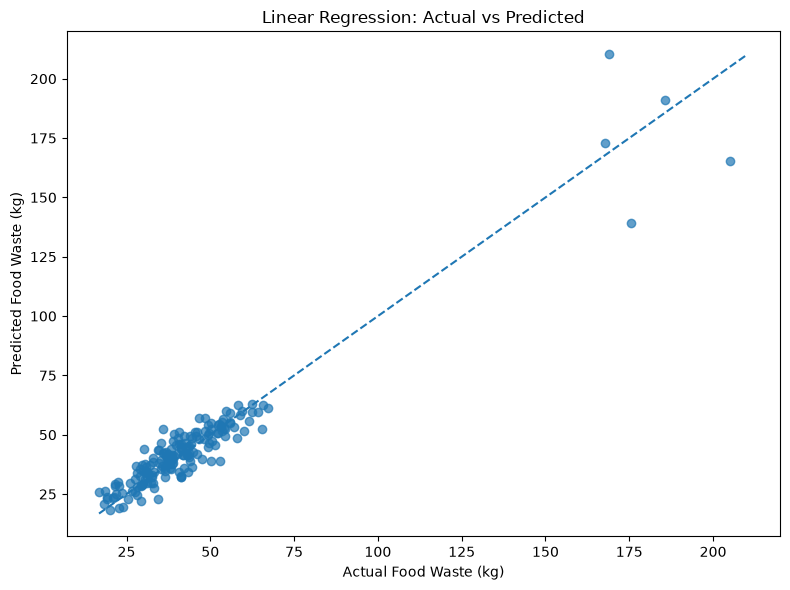

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.7
)

# Ideal prediction reference line
min_value = min(y_test.min(), linear_predictions.min())
max_value = max(y_test.max(), linear_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Food Waste (kg)")
plt.ylabel("Predicted Food Waste (kg)")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()

## Prediction Error Analysis

In [14]:
# Create a detailed prediction error table
error_analysis = pd.DataFrame({
    "ID": test_data["ID"].values,
    "Date": test_data["date"].values,
    "Actual_Waste": y_test.values,
    "Predicted_Waste": linear_predictions
})

# Calculate prediction errors
error_analysis["Error"] = (
    error_analysis["Actual_Waste"]
    - error_analysis["Predicted_Waste"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Display the 10 largest errors
worst_predictions = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

display(worst_predictions.round(2))

,ID,Date,Actual_Waste,Predicted_Waste,Error,Absolute_Error
59,446,2024-03-31,168.87,210.29,-41.42,41.42
106,707,2024-06-14,205.02,165.37,39.66,39.66
39,311,2024-04-12,175.51,139.25,36.25,36.25
23,148,2024-09-11,36.00,52.39,-16.39,16.39
31,222,2024-09-03,30.17,44.17,-14.00,14.00
42,322,2024-03-27,52.83,38.96,13.87,13.87
141,847,2024-05-26,65.43,52.44,12.99,12.99
112,738,2024-05-19,34.47,22.85,11.62,11.62
105,704,2024-07-19,35.26,46.66,-11.40,11.40
152,910,2024-03-15,50.20,38.87,11.33,11.33


## Gradient Boosting Regressor

In [15]:

from sklearn.ensemble import GradientBoostingRegressor

# Numerical preprocessing
gb_numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
gb_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
gb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", gb_numerical_transformer, numerical_features),
        ("cat", gb_categorical_transformer, categorical_features)
    ]
)

# Create Gradient Boosting pipeline
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully!")


Gradient Boosting pipeline created successfully!


In [16]:

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


In [17]:

# Generate predictions
gb_predictions = gradient_boosting_model.predict(X_test)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_test, gb_predictions)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, gb_predictions)
)

gb_r2 = r2_score(y_test, gb_predictions)

# Display results
print("Gradient Boosting Performance")
print("--------------------------------")
print("MAE:", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))


Gradient Boosting Performance
--------------------------------
MAE: 5.0024
RMSE: 8.4497
R2 Score: 0.8949


In [18]:

all_model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

display(
    all_model_results
    .sort_values("RMSE")
    .round(4)
    .reset_index(drop=True)
)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.8026,7.3614,0.9203
1,Random Forest,5.4281,8.4119,0.8959
2,Gradient Boosting,5.0024,8.4497,0.8949


## Save Selected Model

In [19]:

import json
import sklearn
import platform
from datetime import datetime
import os

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save selected Linear Regression pipeline
joblib.dump(
    linear_regression_model,
    "../models/food_waste_model.joblib"
)

# Store selected model information
model_metrics = {
    "model_name": "Linear Regression",
    "model_version": "1.0",
    "target_variable": "food_waste_kg",
    "evaluation_method": "Chronological 80:20 split",
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "mae": float(linear_mae),
    "rmse": float(linear_rmse),
    "r2_score": float(linear_r2),
    "features": X_train.columns.tolist(),
    "training_date": datetime.now().isoformat(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__
}

# Save metrics
with open("../models/metrics.json", "w") as file:
    json.dump(model_metrics, file, indent=4)

# Save comparison of all three models
all_model_results.to_csv(
    "../models/model_comparison.csv",
    index=False
)

print("Selected model and evaluation results saved!")


Selected model and evaluation results saved!


In [20]:

# Check whether files exist
print("Model file exists:",
      os.path.exists("../models/food_waste_model.joblib"))

print("Metrics file exists:",
      os.path.exists("../models/metrics.json"))

print("Comparison file exists:",
      os.path.exists("../models/model_comparison.csv"))

# Load saved model
loaded_model = joblib.load(
    "../models/food_waste_model.joblib"
)

# Generate a sample prediction
sample_input = X_test.iloc[[0]]

sample_prediction = loaded_model.predict(sample_input)

print("\nSample prediction:",
      round(float(sample_prediction[0]), 2), "kg")

print("Actual food waste:",
      round(float(y_test.iloc[0]), 2), "kg")

print("\nModel verification completed!")


Model file exists: True
Metrics file exists: True
Comparison file exists: True

Sample prediction: 39.26 kg
Actual food waste: 38.22 kg

Model verification completed!
